# 4 · The PINN as a surrogate

Batched lift, Newton on the incidence with autograd derivatives, and the cost model. Timings
come from the benchmark's record (`validation/results/compute_budget.csv`, phase4), not from
this notebook, so it rebuilds identically. See
[Lesson 4](../docs/lessons/04-surrogates-in-a-design-loop.md) and
[docs/surrogate.md](../docs/surrogate.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"
from pinncfd.external.geometry import naca, solve_panels
from pinncfd.pinn_airfoil_flowfield import AirfoilPINN, family
from pinncfd.surrogate import break_even, cl_circulation, cl_pressure, solve_alpha

model, _ = io.load_checkpoint(CK / "phase3_champion_s0.pt", AirfoilPINN, DEVICE)

Lift of 200 random sections in one call, against 400 and 16 panels:

In [2]:
q = family.uniform(200, np.random.default_rng(4))
def panel_cl(n):
    return np.array([solve_panels(naca(m, p, t).coordinates(n), a).cl for m, p, t, a in q])
ref, coarse = panel_cl(400), panel_cl(16)
for name, cl in (("PINN, pressure", cl_pressure(model, q, DEVICE)),
                 ("PINN, circulation", cl_circulation(model, q, DEVICE)),
                 ("panel, 16 panels", coarse)):
    print(f"{name:18s} mean |cl error| {np.abs(cl - ref).mean():.4f}")

PINN, pressure     mean |cl error| 0.0316
PINN, circulation  mean |cl error| 0.0376
panel, 16 panels   mean |cl error| 0.0225


The incidence for $c_l = 0.8$ on the six test sections, all at once by Newton:

In [3]:
q0 = np.array([[*family._naca(code, 0.0).params[:3], 0.0] for code in family.TEST_SECTIONS])
alpha, cl, n_eval = solve_alpha(model, q0, 0.8, DEVICE)
print(f"{n_eval} batched evaluations")
for code, row, a in zip(family.TEST_SECTIONS, q0, alpha):
    check = solve_panels(naca(*row[:3]).coordinates(200), a).cl
    print(f"NACA {code}: alpha = {a / DEG:6.3f} deg, panel cl there = {check:.3f}")

4 batched evaluations
NACA 0012: alpha =  6.673 deg, panel cl there = 0.806
NACA 1408: alpha =  5.936 deg, panel cl there = 0.819
NACA 2412: alpha =  4.660 deg, panel cl there = 0.823
NACA 3315: alpha =  3.500 deg, panel cl there = 0.807
NACA 4415: alpha =  2.318 deg, panel cl there = 0.822
NACA 5518: alpha =  0.796 deg, panel cl there = 0.851


Timings and break-even counts from the benchmark record:

In [4]:
rows = {r["case"]: r for r in io.read_budget() if r["phase"] == "phase4"}
t = {k: float(r["time_total_s"]) for k, r in rows.items()}
per_pinn = t["pinn_gpu_x10000"] / 1e4
train_s = float(next(r for r in io.read_budget() if r["phase"] == "phase3" and r["case"] == "champion" and r["seed"] == "0")["time_total_s"])
# 16 panels: the panel-count sweep; 200 panels: the 10^4-evaluation timing (as in Lesson 4)
for n_pan, t_pan in ((16, t["panel_N16"]), (200, t["panel_x10000"] / 1e4)):
    print(f"{n_pan:3d} panels: {1e3 * t_pan:.2f} ms/case, PINN {1e6 * per_pinn:.0f} us/case, "
          f"break-even {break_even(train_s, t_pan, per_pinn):,.0f} evaluations")

 16 panels: 0.39 ms/case, PINN 154 us/case, break-even 2,803,737 evaluations
200 panels: 7.99 ms/case, PINN 154 us/case, break-even 83,739 evaluations


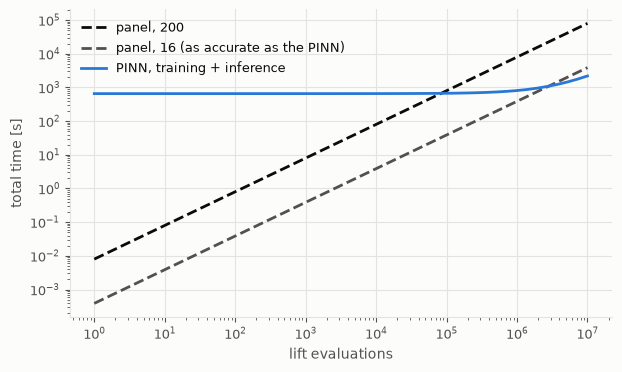

In [5]:
n = np.logspace(0, 7, 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(n, n * t["panel_x10000"] / 1e4, "--", color=P.REFERENCE, label="panel, 200")
ax.loglog(n, n * t["panel_N16"], "--", color=P.TEXT_MUTED, label="panel, 16 (as accurate as the PINN)")
ax.loglog(n, train_s + n * per_pinn, color=P.SERIES[0], label="PINN, training + inference")
ax.set_xlabel("lift evaluations"); ax.set_ylabel("total time [s]"); ax.legend();